# **Grad-CAM**

In [2]:
import os, gc, subprocess, platform
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from PIL import Image
from sklearn.metrics import balanced_accuracy_score

# ── Rutas ─────────────────────────────────────────────────────────────────────
REPO_ROOT = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'],
                                 capture_output=True, text=True).stdout.strip())
if platform.system() == 'Windows':
    DATA_PATH = Path(r'C:\Users\Victoria\Desktop\Dataset ICBA Folds') / 'test'
else:
    DATA_PATH = Path.home() / 'pfc' / 'Dataset ICBA Folds' / 'test'

CNN_DIR   = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 2' / 'Modelo CNN'
CVNXT_DIR = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 2' / 'Modelo Preentrenado'

CLASSES    = ['Am', 'HTA', 'EAo', 'MCH']
ALPHA      = 0.4
AUTOTUNE   = tf.data.AUTOTUNE
BATCH_SIZE = 8


In [3]:
# ── Carga de imágenes de test ─────────────────────────────────────────────────
def load_test_images(test_dir, classes):
    X, y, names = [], [], []
    for label_idx, cls in enumerate(classes):
        for f in sorted((Path(test_dir) / cls).iterdir()):
            if f.suffix.lower() in ('.jpg', '.jpeg'):
                img = np.array(Image.open(f).convert('L'))
                X.append(img)
                y.append(label_idx)
                names.append(f'{cls}/{f.name}')
    return np.array(X, dtype=np.uint8), np.array(y, dtype=np.int32), names

X_test, y_test, img_names = load_test_images(DATA_PATH, CLASSES)

# ── Carga de modelos ──────────────────────────────────────────────────────────
cnn_model   = tf.keras.models.load_model(CNN_DIR   / 'CNN-FINAL.keras',   compile=False)
cvnxt_model = tf.keras.models.load_model(CVNXT_DIR / 'CVNXT-FINAL.keras', compile=False)

## **SELECCIÓN DE CAPA OBJETIVO**

Para determinar la capa objetivo de Grad-CAM en cada arquitectura, se visualizó la resolución espacial de los feature maps de diferentes capas superpuesta sobre una imagen de ECG, con el fin de evaluar qué nivel de detalle permite distinguir estructuras individuales del trazado.

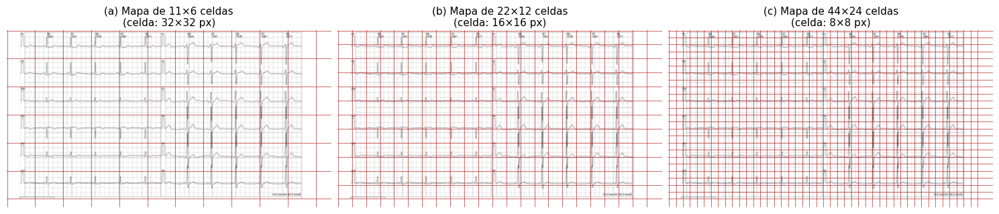

In [3]:
# ── Resolución del mapa de características según capa objetivo ────────────────
# Imagen de ejemplo con complejos QRS de gran amplitud, para apreciar el tamaño
# de cada celda respecto del trazado
RES_IMAGE = 'MCH/MCH_12.jpg'
img_res   = X_test[img_names.index(RES_IMAGE)]
H, W = img_res.shape  # 192 (alto) × 352 (ancho)

GRID_COLOR = '#B11919'

resolutions = [(11, 6), (22, 12), (44, 24)]  # (ancho, alto)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, letra, (fw, fh) in zip(axes, 'abc', resolutions):
    ax.imshow(img_res, cmap='gray', vmin=0, vmax=255)
    for x in np.linspace(0, W, fw + 1):
        ax.axvline(x, color=GRID_COLOR, linewidth=0.5, alpha=0.9)
    for y in np.linspace(0, H, fh + 1):
        ax.axhline(y, color=GRID_COLOR, linewidth=0.5, alpha=0.9)
    cell_w, cell_h = W // fw, H // fh
    ax.set_title(f'({letra}) Mapa de {fw}×{fh} celdas\n(celda: {cell_w}×{cell_h} px)', fontsize=11, pad=4)
    ax.axis('off')

plt.subplots_adjust(left=0.01, right=0.99, top=0.88, bottom=0.01, wspace=0.02)
out_path = REPO_ROOT / 'Informe Final' / 'Imágenes' / 'Resolución Mapa Grad-CAM.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()

A partir de lo observado, se adoptó como criterio seleccionar la **capa más profunda cuya resolución espacial fuera suficiente para distinguir derivaciones individuales** en el electrocardiograma. Para el modelo preentrenado, el cual posee un mayor downsampling (stride ×32), esto implicó retroceder a la penúltima etapa, obteniendo un mapa de 22×12 celdas (16×16 px por celda). Por su parte, como la CNN propia presenta un menor downsampling (stride ×8), la última capa convolucional ya cumplía el criterio con un mapa de 44×24 celdas (8×8 px por celda).

De este modo, las capas seleccionadas para cada modelo son:

- **CNN propia** → `re_lu_7` (feature map: 44×24)
- **ConvNeXtTiny** → `convnext_tiny_stage_2_block_8_identity` (feature map: 22×12)

## **CONSTRUCCIÓN DE MAPAS DE CALOR**

Se reconstruye el grafo de cómputo de cada modelo exponiendo la salida de la capa objetivo, de modo que el `GradientTape` pueda registrar los gradientes respecto de esa activación convolucional. A partir de estos modelos auxiliares se calcula también la inferencia del ensamble sobre todo el conjunto de test, y se definen las funciones auxiliares para generar y superponer los mapas de calor.

Para calcular Grad-CAM se necesita acceder simultáneamente a la salida de la capa objetivo y a la predicción final del modelo. Como los modelos de Keras solo devuelven la predicción, se construye para cada uno un modelo auxiliar con las mismas capas y pesos, pero que devuelve ambas salidas. Esto requiere reconstruir el modelo manualmente, ya que el *backbone* se encuentra anidado dentro del modelo completo.

Con estos modelos auxiliares, `tf.GradientTape` registra las operaciones realizadas durante la predicción y permite calcular el gradiente de la probabilidad de la clase respecto de los mapas de la capa objetivo, que indica la importancia de cada uno de ellos.



In [4]:
# ── Modelos Grad-CAM ──────────────────────────────────────────────────────────
CNN_TARGET_LAYER_INNER   = 're_lu_7'
CVNXT_TARGET_LAYER_INNER = 'convnext_tiny_stage_2_block_8_identity'

backbone_cnn = cnn_model.get_layer('cnn_b_backbone')
backbone_grad_cnn = tf.keras.Model(
    inputs  = backbone_cnn.inputs,
    outputs = [backbone_cnn.get_layer(CNN_TARGET_LAYER_INNER).output, backbone_cnn.output],
)
post_cnn     = [l for l in cnn_model.layers if l.name not in ['input_layer', 'cnn_b_backbone']]
outer_in_cnn = tf.keras.Input(shape=cnn_model.input_shape[1:])
conv_out_cnn, bb_out_cnn = backbone_grad_cnn(outer_in_cnn)
x_cnn = bb_out_cnn
for layer in post_cnn:
    x_cnn = layer(x_cnn)
grad_model_cnn = tf.keras.Model(inputs=outer_in_cnn, outputs=[conv_out_cnn, x_cnn])

backbone_cvnxt = cvnxt_model.get_layer('convnext_tiny')
backbone_grad_cvnxt = tf.keras.Model(
    inputs  = backbone_cvnxt.inputs,
    outputs = [backbone_cvnxt.get_layer(CVNXT_TARGET_LAYER_INNER).output, backbone_cvnxt.output],
)
post_cvnxt     = [l for l in cvnxt_model.layers if l.name not in ['input_layer', 'convnext_tiny']]
outer_in_cvnxt = tf.keras.Input(shape=cvnxt_model.input_shape[1:])
conv_out_cvnxt, bb_out_cvnxt = backbone_grad_cvnxt(outer_in_cvnxt)
x_cvnxt = bb_out_cvnxt
for layer in post_cvnxt:
    x_cvnxt = layer(x_cvnxt)
grad_model_cvnxt = tf.keras.Model(inputs=outer_in_cvnxt, outputs=[conv_out_cvnxt, x_cvnxt])

# ── Inferencia ensamble ───────────────────────────────────────────────────────
X_rgb  = np.stack([X_test, X_test, X_test], axis=-1)
X_gray = X_test[:, :, :, np.newaxis].astype(np.float32) / 255.0

cnn_probs_all   = cnn_model.predict(
    tf.data.Dataset.from_tensor_slices(X_gray).batch(BATCH_SIZE).prefetch(AUTOTUNE), verbose=0)
cvnxt_probs_all = cvnxt_model.predict(
    tf.data.Dataset.from_tensor_slices(X_rgb ).batch(BATCH_SIZE).prefetch(AUTOTUNE), verbose=0)

all_probs_ens = 0.4 * cnn_probs_all + 0.6 * cvnxt_probs_all
all_preds_ens = np.argmax(all_probs_ens, axis=1)

print(f'Bal. Acc ensamble: {balanced_accuracy_score(y_test, all_preds_ens):.4f}')
for i, cls in enumerate(CLASSES):
    mask = y_test == i
    ok   = ((all_preds_ens == y_test) & mask).sum()
    print(f'  {cls}: {ok}/{mask.sum()} correctas')

# ── Funciones auxiliares ──────────────────────────────────────────────────────
def compute_gradcam(grad_model, img_tensor, class_idx=None):
    img_tensor = tf.cast(img_tensor, tf.float32)
    with tf.GradientTape() as tape:
        conv_outputs, preds = grad_model(img_tensor, training=False)
        if class_idx is None:
            class_idx = int(tf.argmax(preds[0]))
        class_score = preds[:, class_idx]
    grads = tape.gradient(class_score, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = conv_outputs[0] @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), class_idx, preds.numpy()[0]

def resize_heatmap(hm, H, W):
    hm_pil = Image.fromarray((hm * 255).astype(np.uint8)).resize((W, H), Image.BILINEAR)
    return np.array(hm_pil, dtype=np.float32) / 255.0

def overlay_heatmap(img_gray_uint8, heatmap, alpha=ALPHA):
    H, W     = img_gray_uint8.shape
    hm       = resize_heatmap(heatmap, H, W) if heatmap.shape != (H, W) else heatmap
    hm_color = plt.cm.jet(hm)[:, :, :3]
    img_rgb  = np.stack([img_gray_uint8] * 3, axis=-1).astype(np.float32) / 255.0
    return np.clip((1 - alpha) * img_rgb + alpha * hm_color, 0, 1)

Bal. Acc ensamble: 0.7809
  Am: 33/37 correctas
  HTA: 27/36 correctas
  EAo: 30/38 correctas
  MCH: 18/26 correctas


A continuación, se presenta la imagen original junto al mapa de calor generado para una imagen del conjunto de prueba.

Imagen : Am_96.jpg
  Am: 0.913
  HTA: 0.074
  EAo: 0.010
  MCH: 0.003


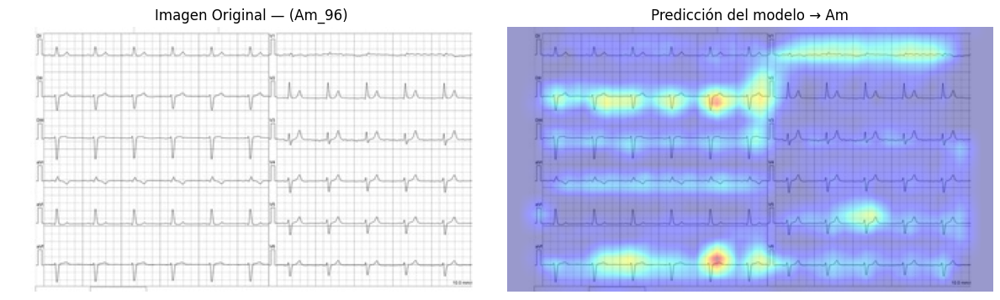

In [56]:
# ── Grad-CAM de una imagen individual ─────────────────────────────────────────
# Editá el path a la imagen que querés analizar
IMG_PATH = DATA_PATH / 'Am' / 'Am_96.jpg'

img      = np.array(Image.open(IMG_PATH).convert('L'))
H, W     = img.shape
true_cls = IMG_PATH.parent.name   # clase real según carpeta ('Am', 'HTA', etc.)

img_cnn   = img[np.newaxis, :, :, np.newaxis].astype(np.float32) / 255.0
img_cvnxt = np.stack([img] * 3, axis=-1)[np.newaxis]

# Inferencia ensamble
p_cnn   = grad_model_cnn(img_cnn,   training=False)[1].numpy()[0]
p_cvnxt = grad_model_cvnxt(img_cvnxt, training=False)[1].numpy()[0]
p_ens   = 0.4 * p_cnn + 0.6 * p_cvnxt
pred    = int(np.argmax(p_ens))

print(f'Imagen : {IMG_PATH.name}')
for i, cls in enumerate(CLASSES):
    print(f'  {cls}: {p_ens[i]:.3f}')

# GradCAM sobre la clase ganadora del ensamble
hm_cnn,   _, _ = compute_gradcam(grad_model_cnn,   img_cnn,   class_idx=pred)
hm_cvnxt, _, _ = compute_gradcam(grad_model_cvnxt, img_cvnxt, class_idx=pred)
hm_ens = 0.4 * resize_heatmap(hm_cnn, H, W) + 0.6 * resize_heatmap(hm_cvnxt, H, W)
hm_ens = hm_ens / (hm_ens.max() + 1e-8)
ov     = overlay_heatmap(img, hm_ens)

pred_color = 'green' if CLASSES[pred] == true_cls else 'red'

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title(f'Imagen Original — ({IMG_PATH.stem})', fontsize=12)
axes[0].axis('off')
axes[1].imshow(ov)
axes[1].set_title(f'Predicción del modelo → {CLASSES[pred]}', fontsize=12)
axes[1].axis('off')
plt.tight_layout()
plt.show()

## **ANÁLISIS DE PATRONES POR CLASE**

Se generan los mapas de Grad-CAM del ensamble sobre las imágenes del conjunto de prueba, con el objetivo de identificar patrones de activación comunes dentro de cada etiología. Para cada clase se presentan, en primer lugar, los mapas de las imágenes correctamente clasificadas, y luego, los mapas de las imágenes incorrectamente clasificadas, lo que permite comparar los patrones de activación entre aciertos y errores.

In [7]:
import gc

CLASSES_FULL = {
    'Am':  'Amiloidosis',
    'HTA': 'Hipertensión Arterial',
    'EAo': 'Estenosis Aórtica',
    'MCH': 'Miocardiopatía Hipertrófica',
}
CLASS_COLORS = {
    'Am':  '#B11919',
    'HTA': '#F16666',
    'EAo': '#0C4AA6',
    'MCH': '#8ECCFF',
}

H, W   = X_test[0].shape
N_COLS = 3


def plot_class_gradcam(cls, correct, n_cols=N_COLS):
    cls_idx  = CLASSES.index(cls)
    mask_cls = y_test == cls_idx
    if correct:
        idx_list = np.where(mask_cls & (all_preds_ens == cls_idx))[0]
        section  = 'correctamente clasificadas'
    else:
        idx_list = np.where(mask_cls & (all_preds_ens != cls_idx))[0]
        section  = 'incorrectamente clasificadas'

    n = len(idx_list)
    if n == 0:
        print(f'{cls}: sin imágenes {section}.')
        return

    n_rows = int(np.ceil(n / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(n_cols * 5, n_rows * 3.5),
                             squeeze=False)

    fig.text(0.02, 1.01, '●', ha='left', va='bottom',
             fontsize=28, color=CLASS_COLORS[cls], transform=fig.transFigure)
    fig.text(0.5, 1.01, f'{CLASSES_FULL[cls]} ({cls})',
             ha='center', va='bottom', fontsize=24, color='black', transform=fig.transFigure)

    for i, idx in enumerate(idx_list):
        r, c = divmod(i, n_cols)
        img = X_test[idx]
        ens_class_idx = int(all_preds_ens[idx])

        img_cnn   = img[np.newaxis, :, :, np.newaxis].astype(np.float32) / 255.0
        img_cvnxt = np.stack([img] * 3, axis=-1)[np.newaxis]

        hm_cnn,   _, probs_cnn   = compute_gradcam(grad_model_cnn,   img_cnn,   class_idx=ens_class_idx)
        hm_cvnxt, _, probs_cvnxt = compute_gradcam(grad_model_cvnxt, img_cvnxt, class_idx=ens_class_idx)

        hm_ens = 0.4 * resize_heatmap(hm_cnn, H, W) + 0.6 * resize_heatmap(hm_cvnxt, H, W)
        hm_ens = hm_ens / (hm_ens.max() + 1e-8)

        probs_ens = 0.4 * probs_cnn + 0.6 * probs_cvnxt
        conf      = probs_ens[ens_class_idx]

        ov       = overlay_heatmap(img, hm_ens, alpha=ALPHA)
        img_name = Path(img_names[idx]).stem

        if correct:
            subtitle = f'{img_name} - p({cls})={probs_ens[cls_idx]:.2f}'
        else:
            subtitle = (f'{img_name} - p({cls})={probs_ens[cls_idx]:.2f}'
                        f' - p({CLASSES[ens_class_idx]})={conf:.2f}')

        axes[r, c].imshow(ov)
        axes[r, c].set_title(subtitle, fontsize=8, color='black')
        axes[r, c].axis('off')
        gc.collect()

    for i in range(n, n_rows * n_cols):
        r, c = divmod(i, n_cols)
        axes[r, c].axis('off')
    plt.tight_layout()
    plt.show()
    gc.collect()


In [63]:
def plot_mean_gradcam(cls):
    """Heatmap promedio del ensamble sobre las correctamente clasificadas de una clase.
    Fondo: la imagen con mayor confianza del ensamble para esa clase."""
    cls_idx  = CLASSES.index(cls)
    idx_list = np.where((y_test == cls_idx) & (all_preds_ens == cls_idx))[0]

    if len(idx_list) == 0:
        print(f'{cls}: sin imágenes correctamente clasificadas.')
        return

    # Imagen representativa: mayor p(cls) según ensamble
    confs   = all_probs_ens[idx_list, cls_idx]
    rep_idx = idx_list[int(np.argmax(confs))]
    rep_img = X_test[rep_idx]

    # Acumular heatmaps
    hm_sum = np.zeros((H, W), dtype=np.float32)
    for idx in idx_list:
        img       = X_test[idx]
        img_cnn   = img[np.newaxis, :, :, np.newaxis].astype(np.float32) / 255.0
        img_cvnxt = np.stack([img] * 3, axis=-1)[np.newaxis]
        hm_cnn,   _, _ = compute_gradcam(grad_model_cnn,   img_cnn,   class_idx=cls_idx)
        hm_cvnxt, _, _ = compute_gradcam(grad_model_cvnxt, img_cvnxt, class_idx=cls_idx)
        hm_sum += 0.4 * resize_heatmap(hm_cnn, H, W) + 0.6 * resize_heatmap(hm_cvnxt, H, W)
        gc.collect()

    hm_mean = hm_sum / len(idx_list)
    hm_mean = hm_mean / (hm_mean.max() + 1e-8)
    ov = overlay_heatmap(rep_img, hm_mean, alpha=ALPHA)

    fig, ax = plt.subplots(1, 1, figsize=(8, 3.5))
    fig.text(0.02, 1.01, '●', ha='left', va='bottom',
             fontsize=18, color=CLASS_COLORS[cls], transform=fig.transFigure)
    fig.text(0.5, 1.01,
             f'{CLASSES_FULL[cls]} ({cls}) — Activación Promedio',
             ha='center', va='bottom', fontsize=16,
             color='black', transform=fig.transFigure)
    ax.imshow(ov)
    ax.set_title(
        f'Fondo: {Path(img_names[rep_idx]).stem}  (p={confs.max():.2f})',
        fontsize=9, color='black')
    ax.axis('off')
    plt.tight_layout()
    plt.show()
    gc.collect()


### Amiloidosis (Am)

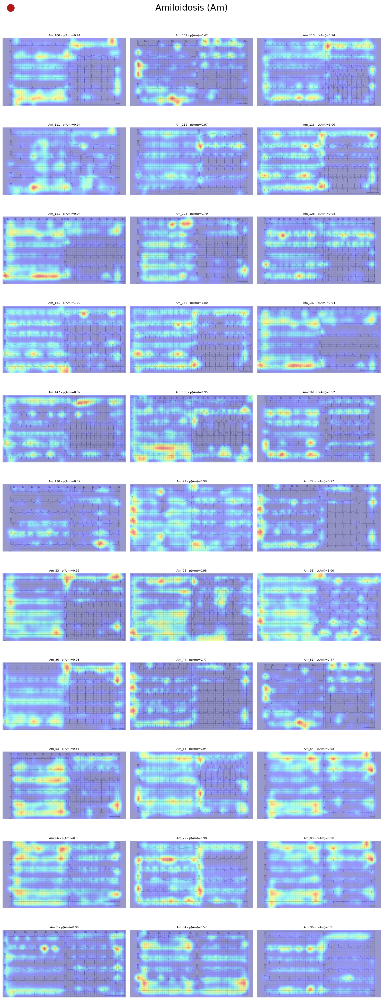

In [43]:
plot_class_gradcam('Am', correct=True)

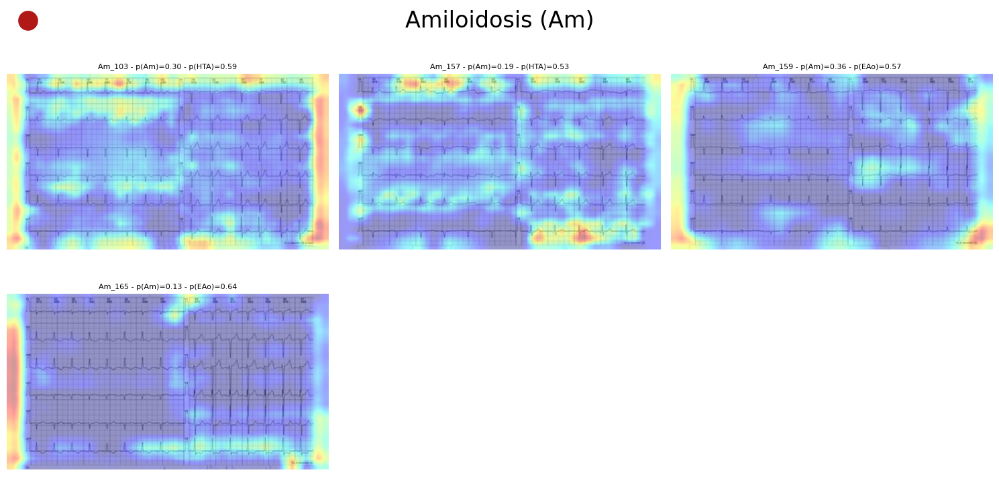

In [44]:
plot_class_gradcam('Am', correct=False)

### Hipertensión Arterial (HTA)

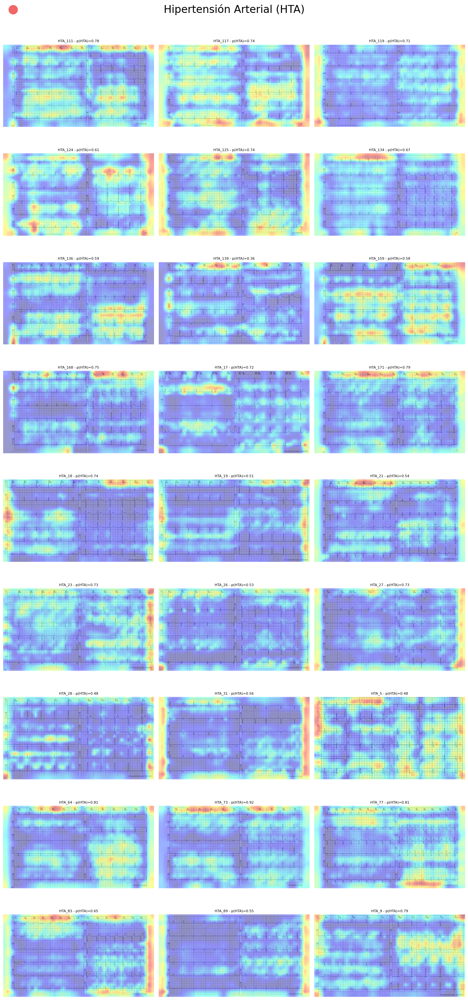

In [45]:
plot_class_gradcam('HTA', correct=True)

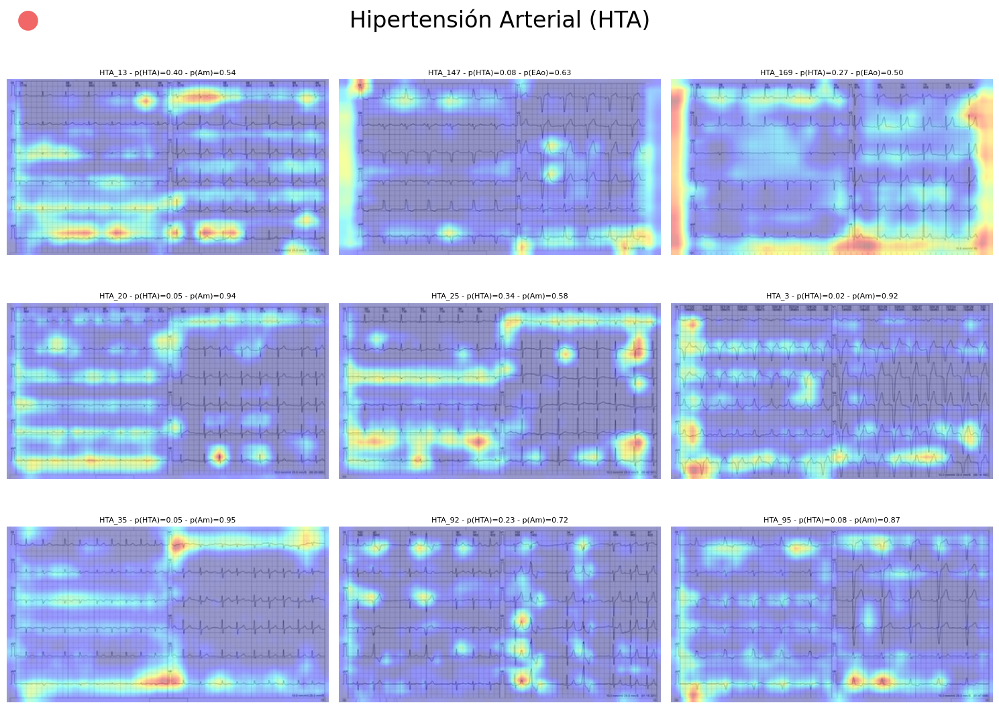

In [46]:
plot_class_gradcam('HTA', correct=False)

### Estenosis Aórtica (EAo)

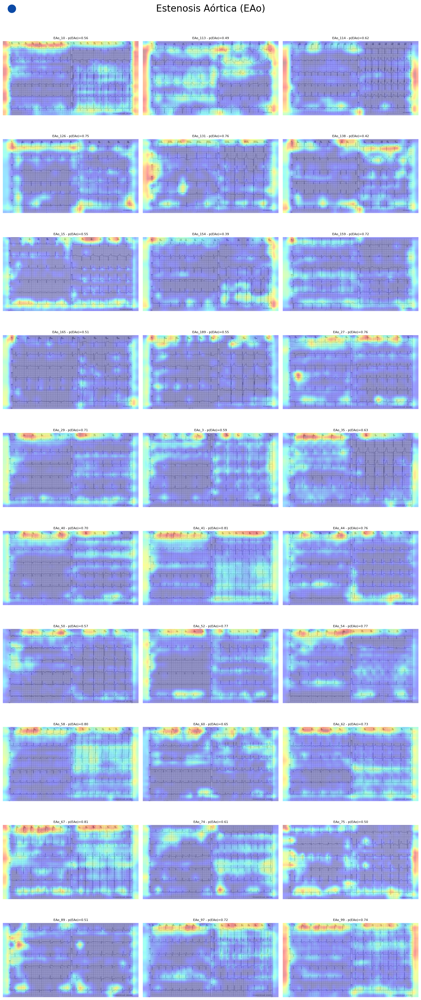

In [39]:
plot_class_gradcam('EAo', correct=True)

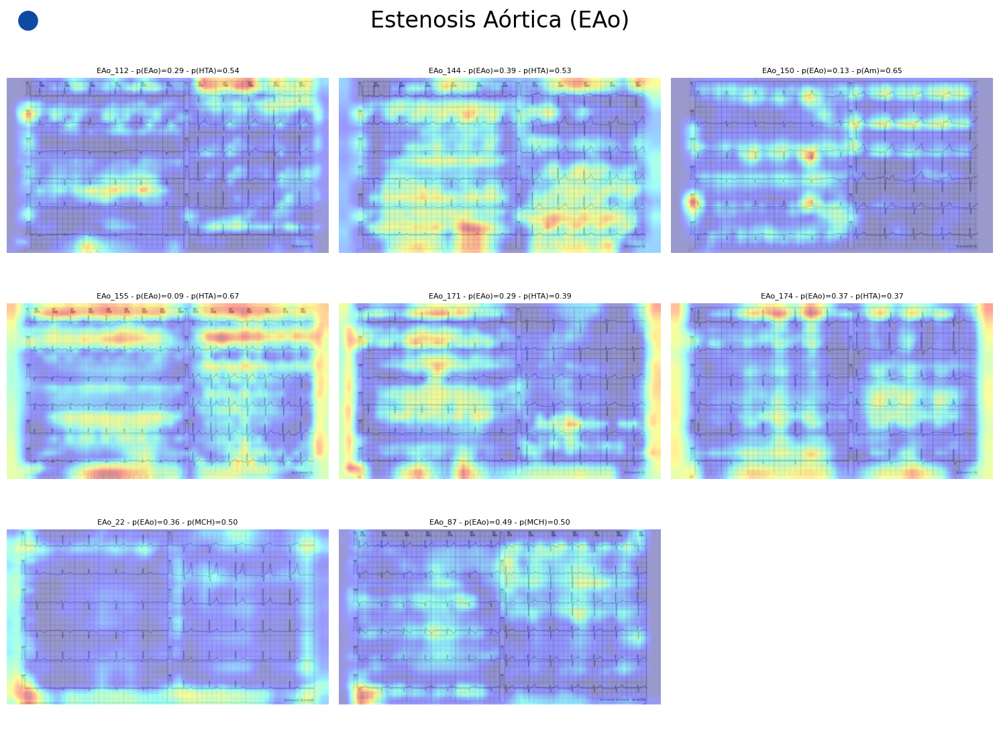

In [40]:
plot_class_gradcam('EAo', correct=False)

### Miocardiopatía Hipertrófica (MCH)

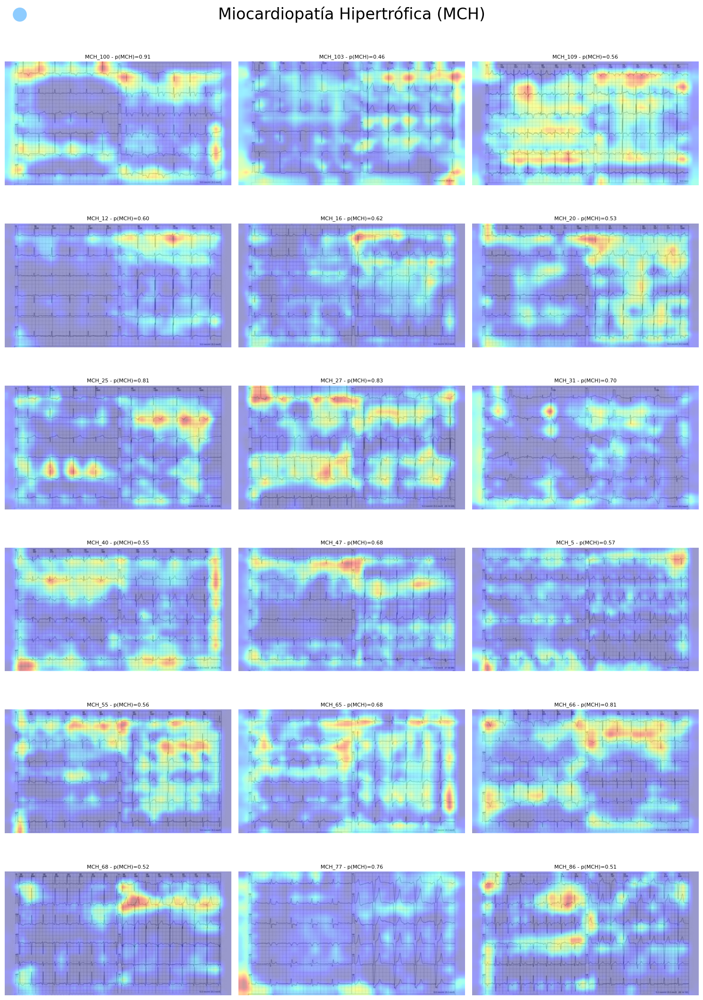

In [41]:
plot_class_gradcam('MCH', correct=True)

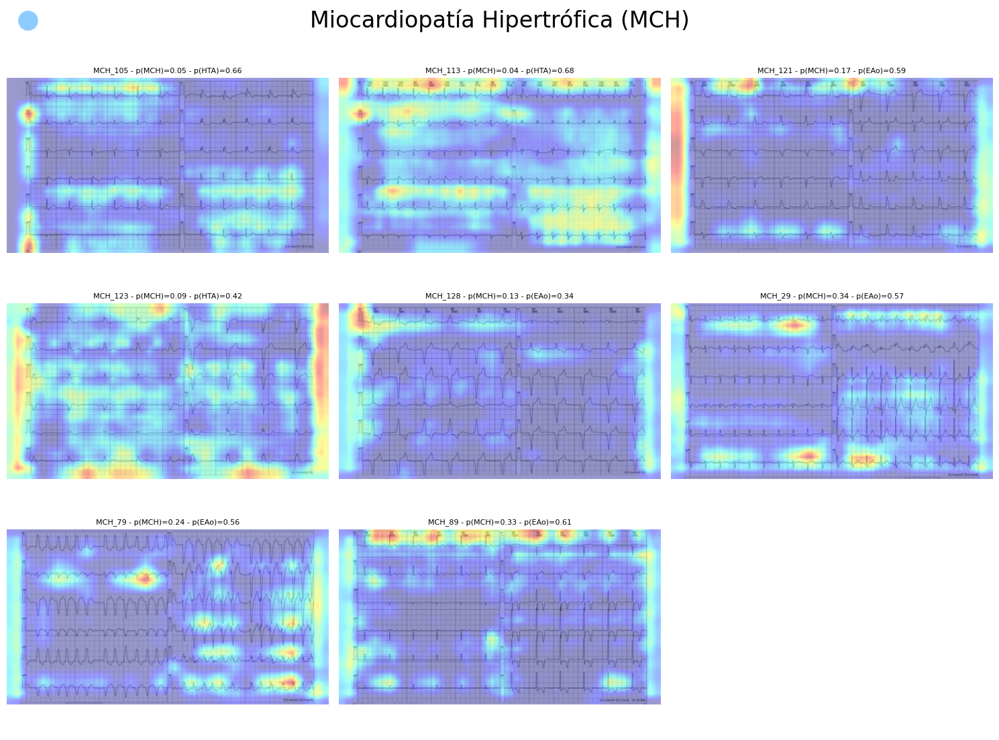

In [42]:
plot_class_gradcam('MCH', correct=False)

A modo de síntesis, se seleccionó una imagen representativa de cada clase para las imágenes correctamente clasificadas y otra para las incorrectamente clasificadas, y se generaron sus mapas de Grad-CAM del ensamble. En el caso de las incorrectas, sobre cada imagen se indica la clase real y la clase predicha, junto con la probabilidad asignada a cada una. Estas figuras corresponden a las presentadas en la sección de Resultados del informe.

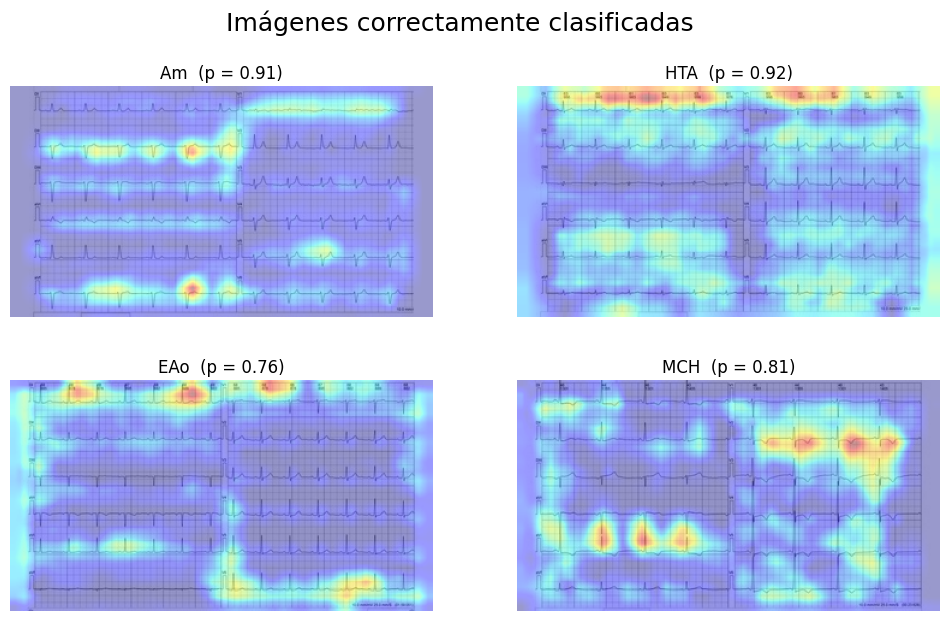

Guardado en C:\Users\Victoria\Desktop\TESIS_bioingenieria_JonquieresOrsi\Informe Final\Imágenes\GradCAM Correctas.png


In [4]:
# ── Correctamente clasificadas (2×2) ─────────────────────────────────────────
CORRECT_IMAGES = [
    ('Am',  'Am_96.jpg'),
    ('HTA', 'HTA_73.jpg'),
    ('EAo', 'EAo_44.jpg'),
    ('MCH', 'MCH_25.jpg'),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
fig.suptitle('Imágenes correctamente clasificadas', fontsize=18)

for ax, (cls, fname) in zip(axes.flat, CORRECT_IMAGES):
    img_path = DATA_PATH / cls / fname
    img      = np.array(Image.open(img_path).convert('L'))
    H, W     = img.shape
    cls_idx  = CLASSES.index(cls)

    img_cnn   = img[np.newaxis, :, :, np.newaxis].astype(np.float32) / 255.0
    img_cvnxt = np.stack([img] * 3, axis=-1)[np.newaxis]

    hm_cnn,   _, probs_cnn   = compute_gradcam(grad_model_cnn,   img_cnn,   class_idx=cls_idx)
    hm_cvnxt, _, probs_cvnxt = compute_gradcam(grad_model_cvnxt, img_cvnxt, class_idx=cls_idx)
    hm_ens = 0.4 * resize_heatmap(hm_cnn, H, W) + 0.6 * resize_heatmap(hm_cvnxt, H, W)
    hm_ens = hm_ens / (hm_ens.max() + 1e-8)
    probs_ens = 0.4 * probs_cnn + 0.6 * probs_cvnxt

    ax.imshow(overlay_heatmap(img, hm_ens))
    ax.set_title(f'{cls}  (p = {probs_ens[cls_idx]:.2f})', fontsize=12)
    ax.axis('off')
    gc.collect()

out_path = REPO_ROOT / 'Informe Final' / 'Imágenes' / 'GradCAM Correctas.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Guardado en {out_path}')

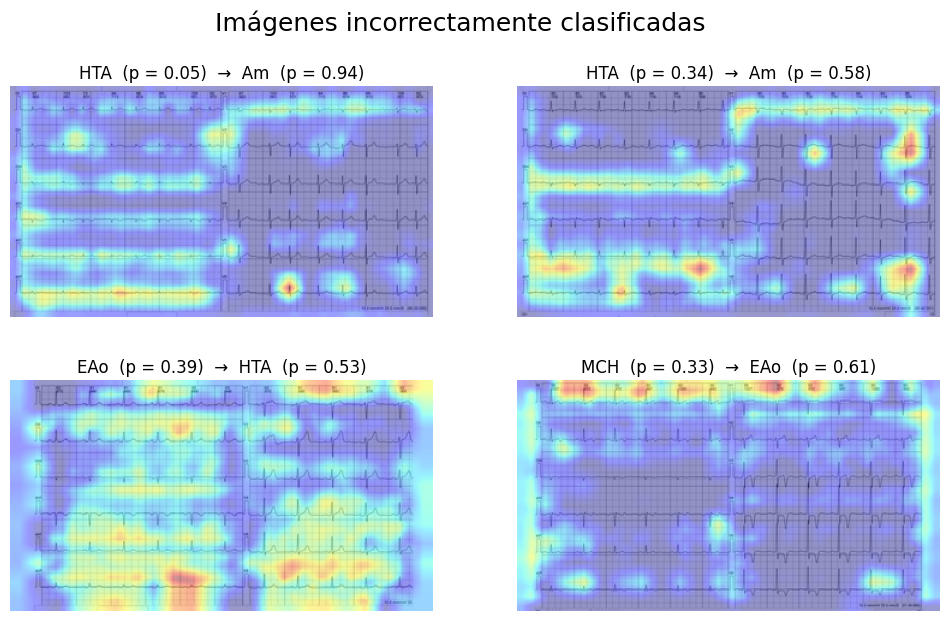

Guardado en C:\Users\Victoria\Desktop\TESIS_bioingenieria_JonquieresOrsi\Informe Final\Imágenes\GradCAM Incorrectas Margen.png


In [ ]:
# ── Incorrectamente clasificadas ──────────────────
INCORRECT_IMAGES = [
    ('HTA',  'HTA_20.jpg'),
    ('HTA', 'HTA_25.jpg'),
    ('EAo', 'EAo_144.jpg'),
    ('MCH', 'MCH_89.jpg'),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
fig.suptitle('Imágenes incorrectamente clasificadas', fontsize=18)

for ax, (cls, fname) in zip(axes.flat, INCORRECT_IMAGES):
    img_path = DATA_PATH / cls / fname
    img      = np.array(Image.open(img_path).convert('L'))
    H, W     = img.shape
    cls_idx  = CLASSES.index(cls)

    img_cnn   = img[np.newaxis, :, :, np.newaxis].astype(np.float32) / 255.0
    img_cvnxt = np.stack([img] * 3, axis=-1)[np.newaxis]

    p_cnn_all   = grad_model_cnn(img_cnn,     training=False)[1].numpy()[0]
    p_cvnxt_all = grad_model_cvnxt(img_cvnxt, training=False)[1].numpy()[0]
    probs_ens   = 0.4 * p_cnn_all + 0.6 * p_cvnxt_all
    pred_idx    = int(np.argmax(probs_ens))

    hm_cnn,   _, _ = compute_gradcam(grad_model_cnn,   img_cnn,   class_idx=pred_idx)
    hm_cvnxt, _, _ = compute_gradcam(grad_model_cvnxt, img_cvnxt, class_idx=pred_idx)
    hm_ens = 0.4 * resize_heatmap(hm_cnn, H, W) + 0.6 * resize_heatmap(hm_cvnxt, H, W)
    hm_ens = hm_ens / (hm_ens.max() + 1e-8)

    ax.imshow(overlay_heatmap(img, hm_ens))
    ax.set_title(
        f'{cls}  (p = {probs_ens[cls_idx]:.2f})  →  {CLASSES[pred_idx]}  (p = {probs_ens[pred_idx]:.2f})',
        fontsize=12)
    ax.axis('off')
    gc.collect()

out_path = REPO_ROOT / 'Informe Final' / 'Imágenes' / 'GradCAM Incorrectas.png'
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f'Guardado en {out_path}')

Además, se generan para el anexo del informe, otras figuras con ejemplos adicionales de los mapas de calor obtenidos para las diferentes clases diagnósticas.

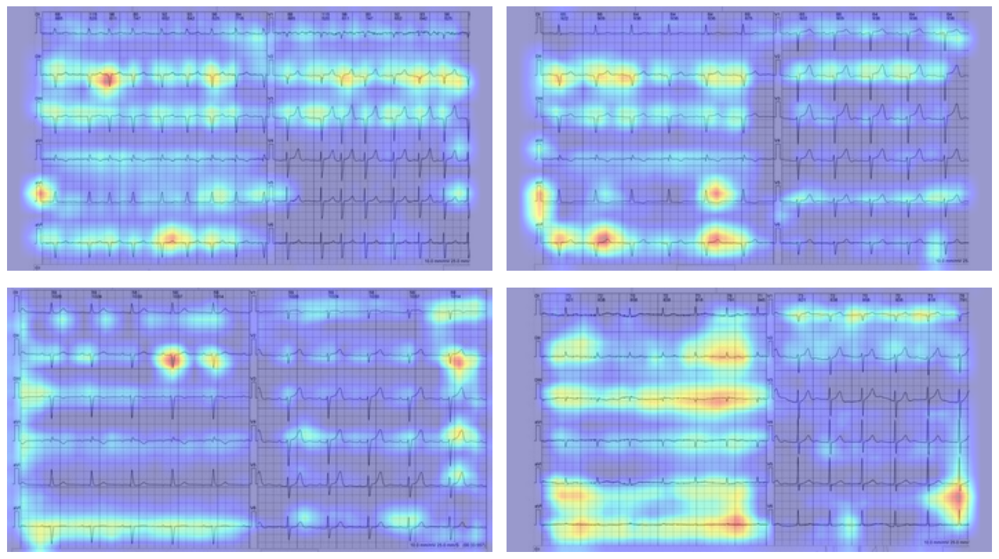

Guardado en C:\Users\Victoria\Desktop\TESIS_bioingenieria_JonquieresOrsi\Informe Final\Imágenes\GradCAM Anexo Am.png


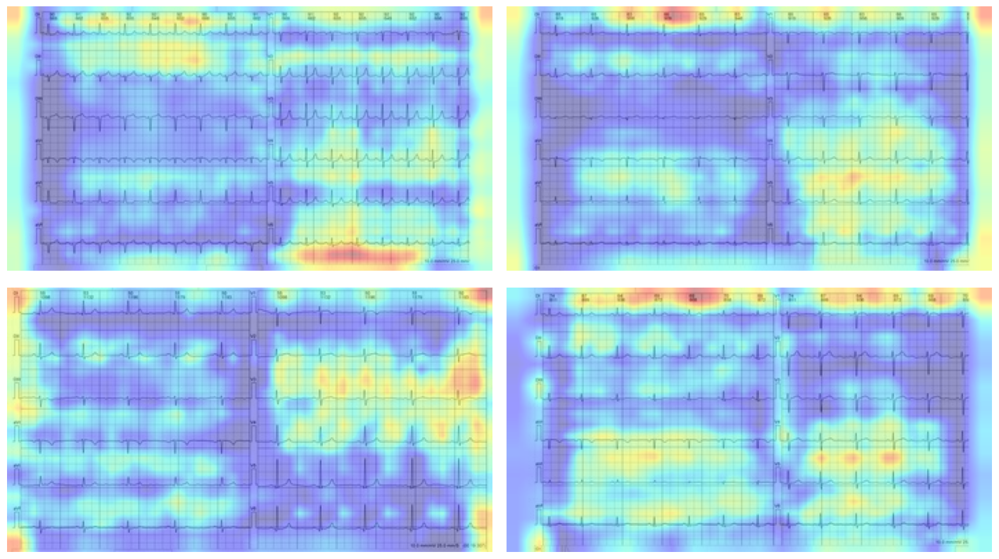

Guardado en C:\Users\Victoria\Desktop\TESIS_bioingenieria_JonquieresOrsi\Informe Final\Imágenes\GradCAM Anexo HTA.png


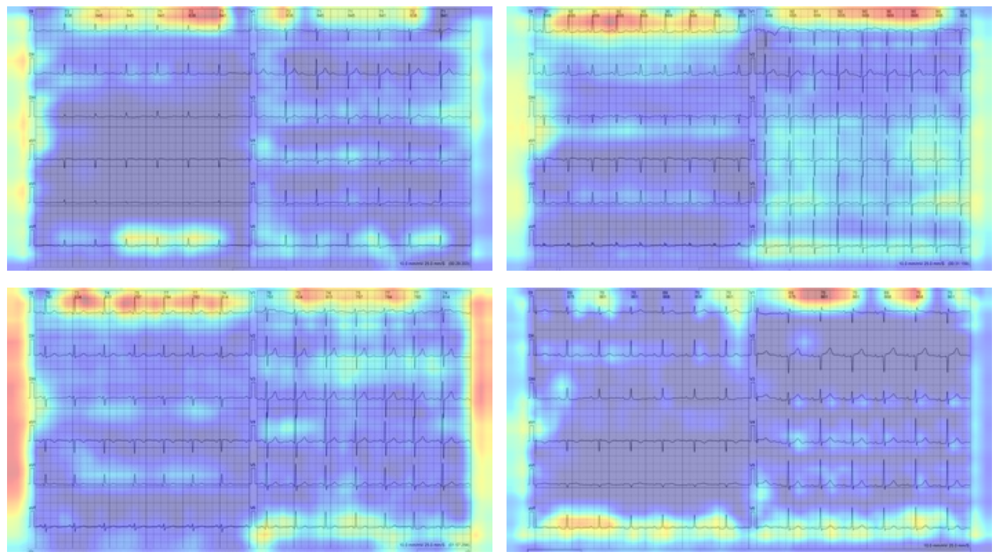

Guardado en C:\Users\Victoria\Desktop\TESIS_bioingenieria_JonquieresOrsi\Informe Final\Imágenes\GradCAM Anexo EAo.png


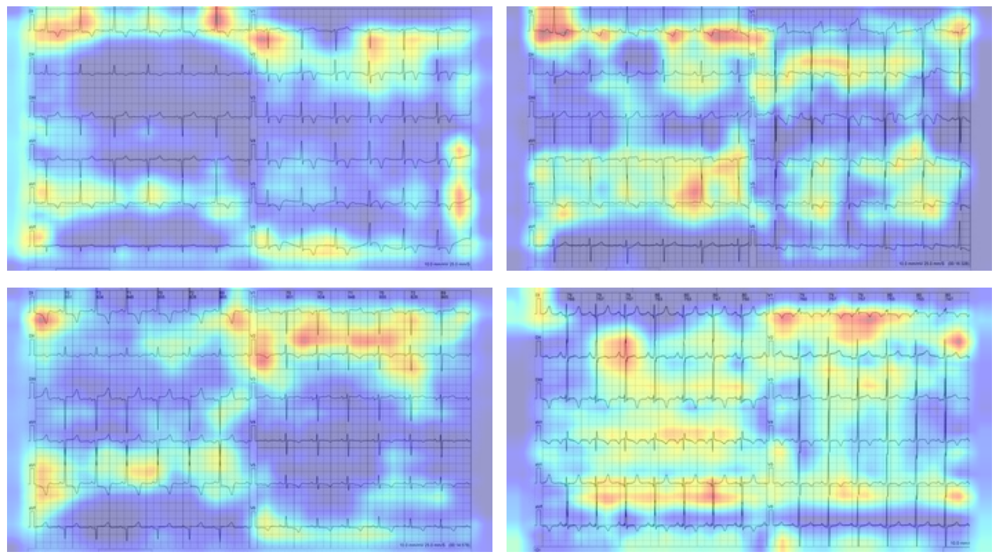

Guardado en C:\Users\Victoria\Desktop\TESIS_bioingenieria_JonquieresOrsi\Informe Final\Imágenes\GradCAM Anexo MCH.png


In [5]:
# ── Anexo: ejemplos adicionales correctamente clasificados (una figura 2×2 por clase) ──
ANEXO_IMAGES = {
    'Am':  ['Am_128.jpg',  'Am_161.jpg',  'Am_9.jpg',   'Am_53.jpg'],
    'HTA': ['HTA_77.jpg',  'HTA_64.jpg',  'HTA_9.jpg',  'HTA_111.jpg'],
    'EAo': ['EAo_52.jpg',  'EAo_41.jpg',  'EAo_99.jpg', 'EAo_15.jpg'],
    'MCH': ['MCH_100.jpg', 'MCH_27.jpg',  'MCH_66.jpg', 'MCH_109.jpg'],
}
ANEXO_FIGURAS = {cls: f'GradCAM Anexo {cls}.png' for cls in ANEXO_IMAGES}   # una figura por clase

# Verificación previa: todas las imágenes deben existir en el conjunto de prueba
faltantes = [f'{cls}/{f}' for cls, files in ANEXO_IMAGES.items()
             for f in files if not (DATA_PATH / cls / f).exists()]
if faltantes:
    raise FileNotFoundError(f'No se encontraron en {DATA_PATH}: {faltantes}')

for cls, fname_out in ANEXO_FIGURAS.items():
    files   = ANEXO_IMAGES[cls]
    fig, axes = plt.subplots(2, 2, figsize=(14, 7.8))
    plt.subplots_adjust(left=0, right=1, bottom=0, top=1, wspace=0.03, hspace=0.05)
    cls_idx = CLASSES.index(cls)

    for ax, fname in zip(axes.flat, files):
        img  = np.array(Image.open(DATA_PATH / cls / fname).convert('L'))
        H, W = img.shape

        img_cnn   = img[np.newaxis, :, :, np.newaxis].astype(np.float32) / 255.0
        img_cvnxt = np.stack([img] * 3, axis=-1)[np.newaxis]

        hm_cnn,   _, _ = compute_gradcam(grad_model_cnn,   img_cnn,   class_idx=cls_idx)
        hm_cvnxt, _, _ = compute_gradcam(grad_model_cvnxt, img_cvnxt, class_idx=cls_idx)
        hm_ens = 0.4 * resize_heatmap(hm_cnn, H, W) + 0.6 * resize_heatmap(hm_cvnxt, H, W)
        hm_ens = hm_ens / (hm_ens.max() + 1e-8)

        ax.imshow(overlay_heatmap(img, hm_ens))
        ax.axis('off')
        gc.collect()

    out_path = REPO_ROOT / 'Informe Final' / 'Imágenes' / fname_out
    plt.savefig(out_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f'Guardado en {out_path}')